# 01 · Exploring MIND and Choosing the slider buckets

OwnFeed lets people steer their feed with 5 sliders. Before building anything, we need to answer:

1. What kinds of articles are in MIND, and which ones do people actually click?
2. How should the MIND categories be grouped into a few slider buckets?
3. Do different users have different tastes? (If everyone liked the same mix, there would be nothing to steer.)
4. Is the mix stable from day to day? 
We only use the **train** data here.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/MINDsmall_train")
FIGURES = Path("../results/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

## Load the data


In [8]:
news = pd.read_csv(
    DATA / "news.tsv", sep="\t", header=None, quoting=3,
    names=["news_id", "category", "subcategory", "title", "abstract", "url", "title_entities", "abstract_entities"],
)
behaviors = pd.read_csv(
    DATA / "behaviors.tsv", sep="\t", header=None,
    names=["impression_id", "user_id", "time", "history", "impressions"],
)
behaviors["time"] = pd.to_datetime(behaviors["time"], format="%m/%d/%Y %I:%M:%S %p")

print(f"{len(news):,} articles, {len(behaviors):,} impressions, {behaviors.user_id.nunique():,} users")
print("Time range:", behaviors.time.min(), "to", behaviors.time.max())
news.head(3)

51,282 articles, 156,965 impressions, 50,000 users
Time range: 2019-11-09 00:00:19 to 2019-11-14 23:59:13


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, and Prince Philip Swear By","Shop the notebooks, jackets, and more that the royals can't live without.",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"", ""Type"": ""P"", ""WikidataId"": ""Q80976"", ""Confidence"": 1.0, ""OccurrenceOffsets"": [48], ""SurfaceForms"": [""Prince Philip""]}, {""Label"": ""Charles, Prince of Wales"", ""Type"": ""P"", ""WikidataId"": ""Q43274"", ""Confidence"": 1.0, ""OccurrenceOffsets"": [28], ""SurfaceForms"": [""Prince Charles""]}, {""Label"": ""Elizabeth II"", ""Type"": ""P"", ""WikidataId"": ""Q9682"", ""Confidence"": 0.97, ""OccurrenceOffsets"": [11], ""SurfaceForms"": [""Queen Elizabeth""]}]",[]
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding you back and keeping you from shedding that unwanted belly fat for good.,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""WikidataId"": ""Q193583"", ""Confidence"": 1.0, ""OccurrenceOffsets"": [20], ""SurfaceForms"": [""Belly Fat""]}]","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""WikidataId"": ""Q193583"", ""Confidence"": 1.0, ""OccurrenceOffsets"": [97], ""SurfaceForms"": [""belly fat""]}]"
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches of Ukraine's War,"Lt. Ivan Molchanets peeked over a parapet of sand bags at the front line of the war in Ukraine. Next to him was an empty helmet propped up to trick snipers, already perforated with multiple holes.",https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId"": ""Q212"", ""Confidence"": 0.946, ""OccurrenceOffsets"": [87], ""SurfaceForms"": [""Ukraine""]}]"


## How many articles are in each category?

In [9]:
news["category"].value_counts()

category
news             15774
sports           14510
finance           3107
foodanddrink      2551
lifestyle         2479
travel            2350
video             2068
weather           2048
health            1885
autos             1639
tv                 889
music              769
movies             606
entertainment      587
kids                17
middleeast           2
northamerica         1
Name: count, dtype: int64

## Which categories do people actually click?

Article counts can mislead: lots of articles doesn't mean lots of interest. So we unpack every impression into one row per *(article shown, clicked or not)* and count clicks.

In [10]:
shown = behaviors[["impression_id", "user_id", "time", "impressions"]].copy()
shown["item"] = shown["impressions"].str.split()
shown = shown.explode("item").drop(columns="impressions")
shown[["news_id", "clicked"]] = shown["item"].str.split("-", expand=True)
shown["clicked"] = shown["clicked"].astype(int)
shown = shown.drop(columns="item").merge(news[["news_id", "category", "subcategory"]], on="news_id", how="left")

by_category = shown.groupby("category").agg(shown=("clicked", "size"), clicks=("clicked", "sum"))
by_category["click_share_%"] = (100 * by_category.clicks / by_category.clicks.sum()).round(1)
by_category["ctr_%"] = (100 * by_category.clicks / by_category.shown).round(2)
by_category.sort_values("clicks", ascending=False)

,shown,clicks,click_share_%,ctr_%
category,,,,
news,1591038,69408,29.4,4.36
sports,592226,28181,11.9,4.76
lifestyle,655440,26584,11.2,4.06
finance,564671,20597,8.7,3.65
music,269008,15988,6.8,5.94
tv,246462,14544,6.2,5.90
foodanddrink,369382,10883,4.6,2.95
health,304088,10863,4.6,3.57
entertainment,349930,10530,4.5,3.01


## Categories and their subcategories

Each category is split into finer **subcategories**. `news`, for example, contains US news, crime, politics, world, science and more. This tells us what is really inside each category before we group them.

First an overview: for each category, how many subcategories it has and which ones get the most clicks (with their share of that category's clicks).

In [11]:
by_sub = shown.groupby(["category", "subcategory"]).agg(shown=("clicked", "size"), clicks=("clicked", "sum")).reset_index()
by_sub["articles"] = by_sub.set_index(["category", "subcategory"]).index.map(news.groupby(["category", "subcategory"]).size())
by_sub["click_share_%"] = (100 * by_sub.clicks / by_sub.clicks.sum()).round(1)
by_sub["share_of_category_%"] = (100 * by_sub.clicks / by_sub.groupby("category").clicks.transform("sum")).round(0)
by_sub["ctr_%"] = (100 * by_sub.clicks / by_sub.shown).round(1)

category_order = by_category.sort_values("clicks", ascending=False).index
by_sub["category"] = pd.Categorical(by_sub["category"], categories=category_order, ordered=True)
by_sub = by_sub.sort_values(["category", "clicks"], ascending=[True, False])

overview = by_sub.groupby("category", observed=True).apply(
    lambda g: pd.Series({
        "subcategories": len(g),
        "category_click_share_%": round(g["click_share_%"].sum(), 1),
        "top_subcategories (share of category)": ", ".join(
            f"{r.subcategory} ({r['share_of_category_%']:.0f}%)"
            for _, r in g.head(5).iterrows()
        ),
    }),
    include_groups=False,
)
pd.set_option("display.max_colwidth", None)
overview

,subcategories,category_click_share_%,top_subcategories (share of category)
category,,,
news,25,29.3,"newsus (37%), newscrime (21%), newsworld (14%), newspolitics (13%), elections-2020-us (5%)"
sports,24,11.8,"football_nfl (55%), football_ncaa (12%), baseball_mlb (8%), basketball_nba (7%), sports_news (5%)"
lifestyle,35,11.1,"lifestyleroyals (29%), lifestylebuzz (27%), shop-holidays (9%), voices (8%), lifestylecelebstyle (5%)"
finance,26,8.6,"finance-companies (47%), markets (17%), finance-real-estate (12%), finance-retirement (6%), personalfinance (6%)"
music,9,6.7,"music-celebrity (52%), musicnews (29%), cma-awards (14%), music-awards (3%), music-gallery (1%)"
tv,10,6.2,"tvnews (45%), tv-celebrity (40%), tv-gallery (8%), topnews (4%), tvvideos (2%)"
foodanddrink,12,4.7,"foodnews (34%), restaurantsandnews (20%), recipes (19%), tipsandtricks (8%), newstrends (6%)"
health,19,4.6,"nutrition (23%), health-news (20%), wellness (17%), weightloss (10%), medical (9%)"
entertainment,11,4.4,"celebrity (44%), entertainment-celebrity (37%), awards (9%), humor (7%), celebhub (1%)"


Now the full table: every subcategory with at least 100 clicks, grouped by category (biggest category first).

In [12]:
pd.set_option("display.max_rows", 200)
by_sub[by_sub.clicks >= 100].set_index(["category", "subcategory"])[
    ["articles", "shown", "clicks", "click_share_%", "share_of_category_%", "ctr_%"]
]

articles   shown  clicks  \
category      subcategory                                          
news          newsus                        6564  482748   25660   
              newscrime                     2254  203292   14343   
              newsworld                     1720  328314    9782   
              newspolitics                  2826  260978    9033   
              elections-2020-us              116   84644    3480   
              newsopinion                    315   28448    2217   
              newsgoodnews                   176   93677    1760   
              newsscienceandtechnology      1210   41965    1373   
              newsphotos                      22   18589     634   
              newsoffbeat                    405   13544     357   
              indepth                          2    4870     303   
              factcheck                       40    7115     168   
sports        football_nfl                  5420  244383   15590   
              football_ncaa                 1665   72461    3398   
              baseball_mlb                  1661   61457    2179   
              basketball_nba                1555   57016    1837   
              sports_news                      4   11929    1296   
              basketball_ncaa                774   30756    1027   
              more_sports                   1065   29942     964   
              icehockey_nhl                  531   22019     599   
              golf                           446    5604     286   
              football_nfl_videos            161   28842     285   
              soccer                         156   11125     240   
              mma                            437    4374     205   
              football_ncaa_videos            36    8182     152   
lifestyle     lifestyleroyals                239  143996    7593   
              lifestylebuzz                  894  143335    7252   
              shop-holidays                  107   85827    2369   
              voices                          86   54555    2211   
              lifestylecelebstyle             59   41560    1459   
              lifestylehomeandgarden         178   39714    1271   
              lifestyledidyouknow            103   21647     794   
              awardstyle                      12   19649     595   
              lifestylepetsanimals            67   15308     540   
              lifestyleparenting              30   17153     412   
              lifestylebeauty                 30   13753     356   
              lifestylevideo                  16    9549     311   
              advice                          25    7090     229   
              lifestylecareer                 30    8596     209   
              lifestylediy                    13    5703     183   
              lifestylefamily                147    4946     172   
              lifestylesmartliving            61    2616     127   
finance       finance-companies              567  165636    9681   
              markets                        410  131682    3526   
              finance-real-estate            584   92118    2536   
              finance-retirement              76   39646    1318   
              personalfinance                118   41695    1144   
              finance-saving-investing        71   25508     816   
              finance-career                  18   11406     304   
              finance-savemoney               65   14730     252   
              finance-taxes                   37    6041     235   
              finance-career-education       118    6927     206   
              finance-insurance               15    5363     124   
              financenews                    697    3044     118   
              finance-top-stocks             117    5830     105   
music         music-celebrity                210   97967    8274   
              musicnews                      414   51629    4665   
              cma-awards    

## Group categories into 5 buckets

Each bucket matches what a user *means* when they move that slider. Most articles are bucketed by their category; a handful of subcategories are moved because they clearly belong elsewhere.

| Bucket | Means | Categories | Subcategories moved in |
|---|---|---|---|
| News | "What's happening" | news, weather | |
| Learn | "Make me smarter" | finance, health | newsscienceandtechnology (from news) |
| Lifestyle | "My everyday life" | lifestyle, foodanddrink, travel, autos | |
| Entertain | "Fun and celebrities" | entertainment, movies, music, tv, video | lifestyleroyals, lifestylebuzz, lifestylecelebstyle, awardstyle (from lifestyle) |
| Sports | "Games and teams" | sports | |

Why the moves: royals/buzz/celeb style are celebrity gossip, so all celebrity content lives in Entertain (turning Entertain down really removes it). Science and tech is the one part of `news` that is about learning, not current events.

`kids`, `northamerica` and `middleeast` have almost no data, so we drop them.

In [13]:
CATEGORY_TO_BUCKET = {
    "news": "News", "weather": "News",
    "finance": "Learn", "health": "Learn",
    "lifestyle": "Lifestyle", "foodanddrink": "Lifestyle", "travel": "Lifestyle", "autos": "Lifestyle",
    "entertainment": "Entertain", "movies": "Entertain", "music": "Entertain", "tv": "Entertain", "video": "Entertain",
    "sports": "Sports",
}
SUBCATEGORY_OVERRIDES = {
    "newsscienceandtechnology": "Learn",
    "lifestyleroyals": "Entertain", "lifestylebuzz": "Entertain", "lifestylecelebstyle": "Entertain", "awardstyle": "Entertain",
}
BUCKET_ORDER = ["News", "Learn", "Lifestyle", "Entertain", "Sports"]

def to_bucket(df):
    # Subcategory override wins; otherwise use the category's bucket
    return df["subcategory"].map(SUBCATEGORY_OVERRIDES).fillna(df["category"].map(CATEGORY_TO_BUCKET))

news["bucket"] = to_bucket(news)
shown["bucket"] = to_bucket(shown)

dropped = news[news.bucket.isna()]
print(f"Dropped {len(dropped)} articles from: {sorted(dropped.category.unique())}")

Dropped 20 articles from: ['kids', 'middleeast', 'northamerica']


In [14]:
by_bucket = shown.groupby("bucket").agg(shown=("clicked", "size"), clicks=("clicked", "sum")).reindex(BUCKET_ORDER)
by_bucket.insert(0, "articles", news.groupby("bucket").size())
by_bucket["click_share_%"] = (100 * by_bucket.clicks / by_bucket.clicks.sum()).round(1)
by_bucket["ctr_%"] = (100 * by_bucket.clicks / by_bucket.shown).round(2)
by_bucket

,articles,shown,clicks,click_share_%,ctr_%
bucket,,,,,
News,16612,1637719,72617,30.7,4.43
Learn,6202,910724,32833,13.9,3.61
Lifestyle,7815,1262809,36300,15.4,2.87
Entertain,6123,1439775,66409,28.1,4.61
Sports,14510,592226,28181,11.9,4.76


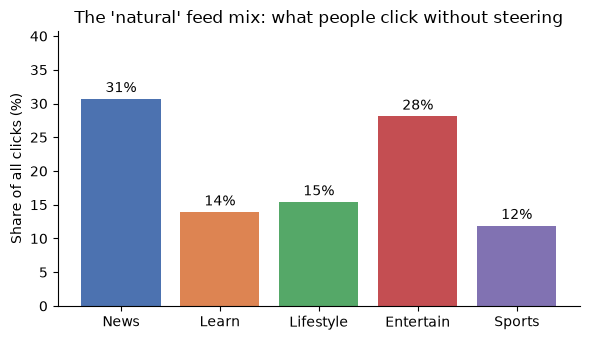

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_bucket.index, by_bucket["click_share_%"], color=["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"])
for i, v in enumerate(by_bucket["click_share_%"]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set_ylabel("Share of all clicks (%)")
ax.set_title("The 'natural' feed mix: what people click without steering")
ax.set_ylim(0, by_bucket["click_share_%"].max() + 10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Step 4: Do users have different tastes?

For each user with at least 5 clicks, we work out *their* bucket mix. If everyone looked like the overall average, sliders would be pointless. A wide spread means people really do want different feeds.

In [16]:
clicks = shown[(shown.clicked == 1) & shown.bucket.notna()]
user_mix = pd.crosstab(clicks.user_id, clicks.bucket, normalize="index").reindex(columns=BUCKET_ORDER, fill_value=0)
active = clicks.user_id.value_counts()
user_mix = user_mix.loc[active[active >= 5].index]

print(f"{len(user_mix):,} users with 5+ clicks")
(100 * user_mix).describe().round(1)

16,158 users with 5+ clicks


bucket,News,Learn,Lifestyle,Entertain,Sports
count,16158.0,16158.0,16158.0,16158.0,16158.0
mean,30.3,14.0,15.8,28.2,11.7
std,21.7,14.6,17.3,21.7,16.7
min,0.0,0.0,0.0,0.0,0.0
25%,14.3,0.0,0.0,12.5,0.0
50%,27.8,12.5,12.5,25.0,0.0
75%,42.9,20.0,23.1,40.0,20.0
max,100.0,100.0,100.0,100.0,100.0


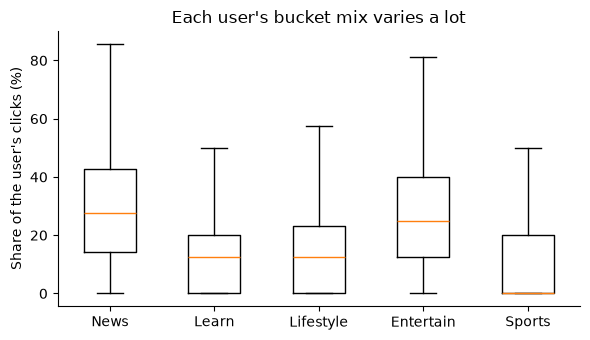

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([100 * user_mix[b] for b in BUCKET_ORDER], tick_labels=BUCKET_ORDER, showfliers=False)
ax.set_ylabel("Share of the user's clicks (%)")
ax.set_title("Each user's bucket mix varies a lot")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

In [19]:
# How often is one bucket most of a user's clicks? 
top_share = user_mix.max(axis=1)
print(f"Users whose top bucket is >50% of their clicks: {100 * (top_share > 0.5).mean():.0f}%")
print(f"Users whose top bucket is >75% of their clicks: {100 * (top_share > 0.75).mean():.0f}%")
user_mix.idxmax(axis=1).value_counts(normalize=True).mul(100).round(1).rename("users_whose_top_bucket_%")

Users whose top bucket is >50% of their clicks: 41%
Users whose top bucket is >75% of their clicks: 8%


News         42.3
Entertain    27.7
Lifestyle    13.0
Learn         9.0
Sports        8.0
Name: users_whose_top_bucket_%, dtype: float64

## Is the mix stable day to day?

Our validation set will be the **last day** of train. If the bucket mix jumped around a lot between days, validation would be measuring a different world than training.

In [20]:
daily = pd.crosstab(clicks.time.dt.date, clicks.bucket, normalize="index").reindex(columns=BUCKET_ORDER).mul(100).round(1)
daily.insert(0, "impressions", behaviors.groupby(behaviors.time.dt.date).size())
daily

bucket,impressions,News,Learn,Lifestyle,Entertain,Sports
time,,,,,,
2019-11-09,13570,34.9,10.0,16.2,30.9,8.0
2019-11-10,15048,35.2,8.5,12.7,33.6,10.0
2019-11-11,32799,28.8,11.5,13.5,27.5,18.7
2019-11-12,33654,32.0,20.1,12.2,22.2,13.5
2019-11-13,31624,30.3,13.3,19.5,27.5,9.3
2019-11-14,30270,27.9,14.3,17.4,32.1,8.4
